# Part B (Mohamad): features, leakage check and Level 1 models
**Kepler KOI exoplanet classification · CMPS 261 project 4.1**

| Step | Plan | What happens |
|---|---|---|
| 0 | – | Setup and data (Hend's split if present, otherwise a temporary split) |
| 1 | M2 | Do the engineered features separate planets from false positives? |
| 2 | M2 | Leakage experiment: same model on 3 feature sets |
| 3 | M3 | Lazy baseline + logistic regression |
| 4 | M4 | Decision tree |
| 5 | M5 | Random Forest + AdaBoost |
| 6 | M6 | Summary table, save models and validation/test probabilities |

Rules followed everywhere: models are **fitted on the training rows only**; hyper-parameters are chosen with
**5-fold cross-validation grouped by star** (`GroupKFold`, Recitation 4); the main metric is **F1** (classes are
imbalanced, Recitation 3). The **test set is not scored here**: its probabilities are only saved for step M7.

## Step 0: setup and data

In [2]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path("..").resolve()                 # repository root (this notebook lives in notebooks/)
sys.path.append(str(ROOT))
from features import (get_X, FEATURES, PHYSICAL, LEAKY_NUMERIC, RANDOM_STATE,
                      make_scaled_pipeline, make_tree_pipeline)

FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "results"; MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [3]:
SPLIT_FILE = ROOT / "data" / "processed" / "koi_split.csv"

if SPLIT_FILE.exists():
    # Hend's official split (P1): columns label (1 = planet) and split (train / val / test)
    df = pd.read_csv(SPLIT_FILE, low_memory=False)
    print("Using Hend's split:", SPLIT_FILE.name)
else:
    # TEMPORARY split, only to test the code. Do NOT report numbers from it.
    print("WARNING: koi_split.csv not found -> TEMPORARY split. Re-run everything once Hend pushes her file.")
    raw = pd.read_csv(ROOT / "data" / "raw" / "cumulative.csv", low_memory=False)
    df = raw[raw["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
    df["label"] = (df["koi_disposition"] == "CONFIRMED").astype(int)
    df = df.reset_index(drop=True)
    rest, test_i = next(GroupShuffleSplit(1, test_size=0.2, random_state=RANDOM_STATE).split(df, groups=df["kepid"]))
    tr, va = next(GroupShuffleSplit(1, test_size=0.25, random_state=RANDOM_STATE).split(df.iloc[rest], groups=df["kepid"].iloc[rest]))
    df["split"] = "test"
    df.loc[df.index[rest[tr]], "split"] = "train"
    df.loc[df.index[rest[va]], "split"] = "val"

train, val, test = (df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"])

# No star may appear in two sets (several KOIs can share a star)
assert not set(train.kepid) & set(val.kepid) and not set(train.kepid) & set(test.kepid) and not set(val.kepid) & set(test.kepid)

X_train, y_train, g_train = get_X(train), train["label"].values, train["kepid"].values
X_val, y_val = get_X(val), val["label"].values
X_test, y_test = get_X(test), test["label"].values

cv = GroupKFold(n_splits=5)      # 5 folds inside TRAIN, all KOIs of one star in the same fold
display(pd.DataFrame({"KOIs": [len(train), len(val), len(test)],
                      "stars": [train.kepid.nunique(), val.kepid.nunique(), test.kepid.nunique()],
                      "planet rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
                     index=["train", "val", "test"]).round(3))

Using Hend's split: koi_split.csv


,KOIs,stars,planet rate
train,4519,3984,0.352
val,1522,1328,0.376
test,1546,1329,0.380


In [4]:
def scores(y, p, threshold=0.5):
    # metrics from Recitation 3: F1 is the main one, the others explain it
    pred = (p >= threshold).astype(int)
    return {"F1": f1_score(y, pred, zero_division=0), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "accuracy": accuracy_score(y, pred)}

results = {}     # model name -> fitted search / model + bookkeeping

## Step 1 (M2): do the engineered features separate planets from false positives?
A real planet must be physically consistent with its star. `density_ratio` compares the star density implied by
the transit with the catalogue density: near 0 for a consistent planet, far from 0 for, e.g., a background
eclipsing binary. Training rows only.

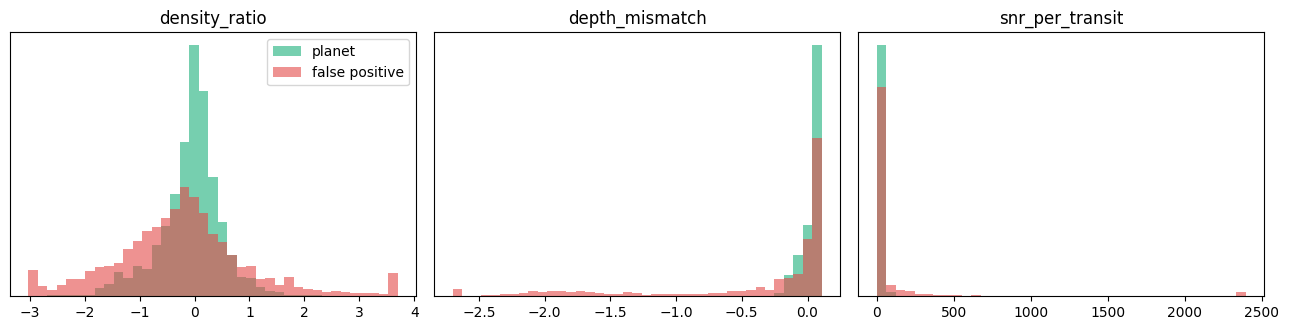

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, ["density_ratio", "depth_mismatch", "snr_per_transit"]):
    v = X_train[c]
    lo, hi = v.quantile(0.01), v.quantile(0.99)
    bins = np.linspace(lo, hi, 40)
    ax.hist(v[y_train == 1].clip(lo, hi).dropna(), bins=bins, alpha=0.6, density=True, label="planet", color="#1baf7a")
    ax.hist(v[y_train == 0].clip(lo, hi).dropna(), bins=bins, alpha=0.6, density=True, label="false positive", color="#e34948")
    ax.set_title(c); ax.set_yticks([])
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG / "B1_engineered_features.png", dpi=200); plt.show()

## Step 2 (M2): leakage experiment
Same Random Forest, same 5 grouped folds, three feature sets:
* **(a) physical only**: the 15 physical columns
* **(b) our final set**: + 3 automatic diagnostics + 3 engineered features (`FEATURES`)
* **(c) + leaky columns**: + `koi_score` and the four `koi_fpflag_*` flags

(c) is expected to be almost perfect, **not** because the model is better but because those columns were produced
by the vetting that decided the label: they contain the answer. A new detection would not have them.

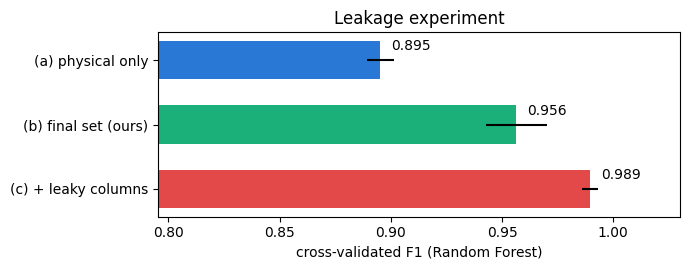

,features,CV F1 mean,CV F1 std
(a) physical only,15.0,0.8954,0.0062
(b) final set (ours),21.0,0.9564,0.0138
(c) + leaky columns,26.0,0.9895,0.0036


In [6]:
rf_fixed = make_tree_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                     random_state=RANDOM_STATE, n_jobs=-1))
feature_sets = {"(a) physical only": PHYSICAL,
                "(b) final set (ours)": FEATURES,
                "(c) + leaky columns": FEATURES + LEAKY_NUMERIC}
leak = {}
for name, cols in feature_sets.items():
    f1s = cross_val_score(rf_fixed, get_X(train, cols), y_train, groups=g_train, cv=cv, scoring="f1")
    leak[name] = {"features": len(cols), "CV F1 mean": f1s.mean(), "CV F1 std": f1s.std()}
leak = pd.DataFrame(leak).T
leak.to_csv(RES / "B2_leakage_experiment.csv")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(leak.index[::-1], leak["CV F1 mean"][::-1], xerr=leak["CV F1 std"][::-1],
        color=["#e34948", "#1baf7a", "#2a78d6"], height=0.6)
for i, v in enumerate(leak["CV F1 mean"][::-1]):
    ax.text(v + 0.005, i + 0.15, f"{v:.3f}")
ax.set_xlim(max(0, leak["CV F1 mean"].min() - 0.1), 1.03); ax.set_xlabel("cross-validated F1 (Random Forest)")
ax.set_title("Leakage experiment")
plt.tight_layout(); plt.savefig(FIG / "B2_leakage.png", dpi=200); plt.show()
leak.round(4)

## Step 3 (M3): lazy baseline and logistic regression
**Baseline** (Recitation 3.1): always predicts the majority class (false positive). Its F1 is 0: every model must beat it.

**Logistic regression** (scaled pipeline): `C = 1/λ` controls regularisation (small C = simpler model);
L1 can set weights exactly to zero (feature selection), L2 shrinks all weights; `class_weight="balanced"` gives the
rarer class (planets) more weight.

In [7]:
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results["Baseline"] = {"model": base, "cv_f1": 0.0, "cv_std": 0.0, "train_f1": 0.0, "seconds": 0.0, "params": "-"}
print("Baseline on validation:", {k: round(v, 3) for k, v in scores(y_val, base.predict_proba(X_val)[:, 1]).items()})

Baseline on validation: {'F1': 0.0, 'precision': 0.0, 'recall': 0.0, 'accuracy': 0.624}


In [8]:
def tune(name, pipeline, grid, random=False, n_iter=20):
    Search = RandomizedSearchCV if random else GridSearchCV
    extra = {"n_iter": n_iter, "random_state": RANDOM_STATE} if random else {}
    search = Search(pipeline, grid, cv=cv, scoring="f1", return_train_score=True, n_jobs=-1, **extra)
    t0 = time.time()
    search.fit(X_train, y_train, groups=g_train)
    seconds = time.time() - t0
    i = search.best_index_
    results[name] = {"model": search.best_estimator_, "search": search, "seconds": seconds,
                     "cv_f1": search.cv_results_["mean_test_score"][i], "cv_std": search.cv_results_["std_test_score"][i],
                     "train_f1": search.cv_results_["mean_train_score"][i], "params": search.best_params_}
    print(f"{name}: CV F1 {results[name]['cv_f1']:.4f} ± {results[name]['cv_std']:.4f} | train F1 "
          f"{results[name]['train_f1']:.4f} | {seconds:.0f}s | best {search.best_params_}")
    return search

# scikit-learn >= 1.8 chooses L1/L2 with l1_ratio (0 = L2, 1 = L1); older versions use penalty
NEW_SK = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)
PEN = {"model__l1_ratio": [0.0, 1.0]} if NEW_SK else {"model__penalty": ["l2", "l1"]}
PEN_KEY = list(PEN)[0]

lr_search = tune("LogReg",
                 make_scaled_pipeline(LogisticRegression(solver="liblinear", max_iter=5000)),
                 {"model__C": [0.001, 0.01, 0.1, 1, 10, 100], **PEN, "model__class_weight": [None, "balanced"]})

LogReg: CV F1 0.9406 ± 0.0114 | train F1 0.9439 | 9s | best {'model__C': 10, 'model__class_weight': None, 'model__l1_ratio': 0.0}


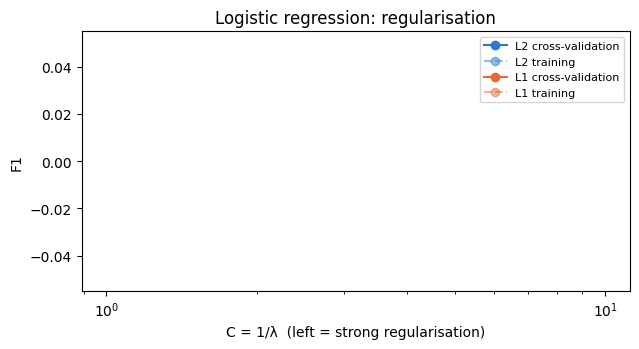

non-zero weights: 40 of 40


In [9]:
r = pd.DataFrame(lr_search.cv_results_)
best_cw = str(lr_search.best_params_["model__class_weight"])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for pen, label, color in [(PEN[PEN_KEY][0], "L2", "#2a78d6"), (PEN[PEN_KEY][1], "L1", "#eb6834")]:
    s = r[(r[f"param_{PEN_KEY}"] == pen) & (r["param_model__class_weight"].astype(str) == best_cw)].sort_values("param_model__C")
    ax.plot(s["param_model__C"].astype(float), s["mean_test_score"], "o-", color=color, label=f"{label} cross-validation")
    ax.plot(s["param_model__C"].astype(float), s["mean_train_score"], "o--", color=color, alpha=0.5, label=f"{label} training")
ax.set_xscale("log"); ax.set_xlabel("C = 1/λ  (left = strong regularisation)"); ax.set_ylabel("F1")
ax.set_title("Logistic regression: regularisation"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "B3_logreg_C.png", dpi=200); plt.show()
w = results["LogReg"]["model"].named_steps["model"].coef_.ravel()
print(f"non-zero weights: {(w != 0).sum()} of {w.size}")

## Step 4 (M4): decision tree
The tree asks yes/no questions chosen by Gini impurity (Recitation 6). Unlimited depth memorises the training data;
`max_depth` and `min_samples_leaf` control that.

DecisionTree: CV F1 0.9249 ± 0.0096 | train F1 0.9627 | 2s | best {'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 1}


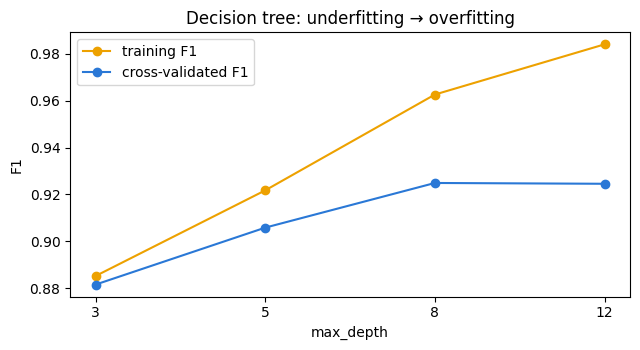

In [10]:
dt_search = tune("DecisionTree",
                 make_tree_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                 {"model__max_depth": [3, 5, 8, 12, None], "model__min_samples_leaf": [1, 10, 50],
                  "model__class_weight": [None, "balanced"]})

r = pd.DataFrame(dt_search.cv_results_)
bp = dt_search.best_params_
s = r[(r["param_model__min_samples_leaf"] == bp["model__min_samples_leaf"]) &
      (r["param_model__class_weight"].astype(str) == str(bp["model__class_weight"]))].copy()
s["depth"] = s["param_model__max_depth"].astype(str)
s = s.set_index("depth").loc[[d for d in ["3", "5", "8", "12", "None"] if d in set(s["depth"])]]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(s.index, s["mean_train_score"], "o-", color="#eda100", label="training F1")
ax.plot(s.index, s["mean_test_score"], "o-", color="#2a78d6", label="cross-validated F1")
ax.set_xlabel("max_depth"); ax.set_ylabel("F1"); ax.set_title("Decision tree: underfitting → overfitting"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "B4_tree_depth.png", dpi=200); plt.show()

## Step 5 (M5): Random Forest and AdaBoost
**Random Forest** (Recitation 6): many trees, each on a bootstrap sample of rows and a random subset of features
per split; their vote reduces the variance of a single tree.
**AdaBoost** (Recitation 6): small trees added one after another, each focusing on the KOIs the previous ones got wrong.
Large search spaces → `RandomizedSearchCV` with a fixed budget of 20 settings (Recitation 4).

In [11]:
rf_search = tune("RandomForest",
                 make_tree_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
                 {"model__n_estimators": [200, 400], "model__max_depth": [None, 10, 20],
                  "model__min_samples_leaf": [1, 3, 5], "model__max_features": ["sqrt", 0.3, 0.5],
                  "model__class_weight": [None, "balanced"]},
                 random=True, n_iter=20)

RandomForest: CV F1 0.9548 ± 0.0104 | train F1 1.0000 | 128s | best {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': None}


In [12]:
ada_search = tune("AdaBoost",
                  make_tree_pipeline(AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                        random_state=RANDOM_STATE)),
                  {"model__estimator__max_depth": [1, 2, 3], "model__n_estimators": [100, 200, 400],
                   "model__learning_rate": [0.1, 0.5, 1.0]},
                  random=True, n_iter=20)

AdaBoost: CV F1 0.9608 ± 0.0080 | train F1 1.0000 | 97s | best {'model__n_estimators': 100, 'model__learning_rate': 1.0, 'model__estimator__max_depth': 3}


## Step 6 (M6): summary, validation scores, save everything
* **CV F1** = mean over the 5 grouped folds of the training set; **train F1 − CV F1** = overfitting gap.
* **Validation F1** at threshold 0.5 (thresholds are tuned later, in M7, on the validation set).
* Each model's validation **and** test probabilities are saved to `results/preds_<Model>.csv` for M7.
  We do **not** look at test scores here.

In [13]:
rows = []
for name, r in results.items():
    p_val = r["model"].predict_proba(X_val)[:, 1]
    v = scores(y_val, p_val)
    rows.append({"model": name, "level": "baseline" if name == "Baseline" else "Level 1",
                 "CV F1": r["cv_f1"], "CV std": r["cv_std"], "train F1": r["train_f1"],
                 "overfit gap": r["train_f1"] - r["cv_f1"], "val F1": v["F1"], "val precision": v["precision"],
                 "val recall": v["recall"], "tuning s": r["seconds"], "best params": str(r["params"])})
summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(RES / "B6_level1_summary.csv")
summary.drop(columns="best params").round(4)

,level,CV F1,CV std,train F1,overfit gap,val F1,val precision,val recall,tuning s
model,,,,,,,,,
Baseline,baseline,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
LogReg,Level 1,0.9406,0.0114,0.9439,0.0033,0.9317,0.9214,0.9423,9.0710
DecisionTree,Level 1,0.9249,0.0096,0.9627,0.0378,0.9131,0.8904,0.9371,2.2293
RandomForest,Level 1,0.9548,0.0104,1.0000,0.0452,0.9512,0.9658,0.9371,128.1222
AdaBoost,Level 1,0.9608,0.0080,1.0000,0.0392,0.9496,0.9446,0.9545,97.3300


In [14]:
for name, r in results.items():
    joblib.dump(r["model"], MODELS / f"{name}.joblib", compress=3)
    parts = []
    for part, X_, y_ in [("val", X_val, y_val), ("test", X_test, y_test)]:
        frame = (val if part == "val" else test)[["kepoi_name", "kepid"]].copy()
        frame["label"], frame["split"], frame["p"] = y_, part, r["model"].predict_proba(X_)[:, 1]
        parts.append(frame)
    pd.concat(parts).to_csv(RES / f"preds_{name}.csv", index=False)
print("saved:", sorted(p.name for p in MODELS.glob("*.joblib")), "and preds_<Model>.csv in results/")

saved: ['AdaBoost.joblib', 'Baseline.joblib', 'DecisionTree.joblib', 'LogReg.joblib', 'RandomForest.joblib'] and preds_<Model>.csv in results/


### What to write in the report (from this notebook)
* Leakage experiment (figure B2): F1 with leaky columns vs our final set, and why the leaky columns are excluded.
* Engineered features (figure B1): `density_ratio` separates planets from false positives.
* For each Level 1 model: why it was chosen, the search grid, the best parameters, CV F1 ± std and the overfitting
  gap (table B6, figures B3–B4).